# <center>**Figure 05 : LAL Network Diagram**</center>

Circuit diagram of the LAL network. Every node is a connectivity group, drawn as a disc of where its inputs sit and a ring of where its outputs sit -- in its own hemisphere or across the midline -- in both hemispheres. Rows run top to bottom by role -- input, hubs, mixed, local, descending -- and within a row the more commissural groups sit closer to the midline.

The image is mirrored, as in the rest of the figure : the **right LAL is on the left of the page**. Edges are the outputs of the right hemisphere (hemisphere-averaged); the left hemisphere is drawn as nodes only. Hemisphere and row names are added in Inkscape.

In [87]:
import sys, os
sys.path.insert(0, os.path.abspath("../Scripts"))
from collections import defaultdict

import numpy as np
import pandas as pd
import networkx as nx

import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import Wedge, Circle, FancyArrowPatch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerPatch
import seaborn as sns
sns.set_style("ticks")

In [88]:
#------------------------------------------------------------------------------
# Plot params
title_fontsize = 8.5
label_fontsize = 7
tick_fontsize  = 6
cbar_fontsize  = 5
panel_h        = 3.0     # inch -- the width follows from the diagram

# Nodes -- radius = node_r0 + node_r1 * sqrt(neurons), in diagram units
node_r0    = 0.16
node_r1    = 0.045
wedge_lw   = 0.3

# Arbor polarity of the classes -- for the VNC stubs
polarity_order = ["Local", "Commissural", "Ipsi_Descending", "Contra_Descending"]

# Node wedges -- synapses in the soma hemisphere or across the midline.
# Inner disc : inputs, outer ring : outputs. Contra is the Contra purple of E
pie_colors = {"Ipsi"   : "#cdcdcd",
              "Contra" : "#7e57a6"}
ring_frac  = 0.35    # Width of the output ring, as a fraction of the node radius

# Edges take the color of the presynaptic group.
# Within a row the shade runs lateral -> medial, dark to light.
edge_colors = {"g105" : "#d7263d",    # Proprioceptive relay
               "g026" : "#2c6f9e",    # Convergence input, with g038
               "g038" : "#2c6f9e",
               "g098" : "#5c2d86",    # Hubs
               "g108" : "#a07abf",
               "g107" : "#145058",    # Mixed -- commissural, with some local
               "g101" : "#0e7578",
               "g099" : "#1a9098",
               "g100" : "#2f9aa8",
               "g106" : "#0e4e27",    # Local
               "g096" : "#1a9e27",
               "g169" : "#66891a",
               "g093" : "#8f4516",    # Descending
               "g094" : "#b35806",
               "g095" : "#de7014",
               "g164" : "#d08c0e",
               "g166" : "#c4a20e",
               "g102" : "#b89a22",
               "g097" : "#c8b034"}

arrow_size = 3.3         # ... plus 0.20 per point of line width, so the head stays off the pie
stub_color = "#555555"   # Descending output to the VNC

# Routing (diagram units) -- every edge is orthogonal with rounded corners,
# and has its own ports, lanes and shaft
corner_r  = 0.1     # Rounded corners
gap_pad   = 0.07    # Lanes keep this far from the nodes
label_h   = 0.3     # Height kept free for the labels above a row
lane_sep  = 0.12    # Clearance between two horizontals that share a lane
shaft_sep = 0.09    # Minimum distance between two shafts
port_step = 0.16    # Spacing of the ports along a node
port_span = 0.95    # ... and at most this fraction of the radius from its centre
top_span  = 0.55    # ... on the top of a node, clear of its label


### Load data

- `Groups_Separated_128_8_Corrected` : Class -> Group
- `Connectivity_Group` : group-to-group synapses, split by hemisphere (`Side` : Ipsi / Contra)
- `Group_Positions` : number of neurons per group (node size)
- `Connectivity_Fragmented_level1` : every synapse with the fragment it sits on (axon / dendrite) and its compartment (node discs and rings, and the axo panel)

In [89]:
groups = pd.read_csv("../Analysis_Outputs/Embedding/Groups_Separated_128_8_Corrected.csv")
groups["Group"] = groups["Group"].apply(lambda g : f"g{g:03d}")

conn = pd.read_parquet("../Data_Connectivity/Connectivity_Group.parquet")
conn["Side"] = np.where(conn["Hemisphere_pre"] == conn["Hemisphere_post"], "Ipsi", "Contra")

pos  = pd.read_parquet("../Analysis_Outputs/Group_Anatomy/Group_Positions.parquet")
size = pos.loc[pos["Fragment"] == "Neuron"].groupby("Group")["Size"].mean()

### Layout

Rows, top to bottom : Input (g038, g026, g105) -> Hubs (g108, g098) -> Mixed (g100, g099, g101, g107) -> Local (g169, g096, g106) -> Descending.

x is given for the right hemisphere (left of the page, x < 0); the left hemisphere is its mirror image. g105 and g093 sit on the lateral edge.

In [90]:
# Rows, top -> bottom
lal_rows = {"Input"      : ["g038", "g026", "g105"],
            "Hubs"       : ["g108", "g098"],
            "Mixed"      : ["g100", "g099", "g101", "g107"],
            "Local"      : ["g169", "g096", "g106"],
            "Descending" : ["g097", "g102", "g166", "g164", "g095", "g094", "g093"]}

# Mixed sits closer to the hubs -- that gap has few lanes, the one below it has the most
row_y = {"Input"      : 8.0,
         "Hubs"       : 6.2,
         "Mixed"      : 4.75,
         "Local"      : 2.6,
         "Descending" : 0.4}

# x in the right hemisphere (paper left, x < 0) -- the left hemisphere is its mirror image
x_pos = {"g038" : -1.6, "g026" : -3.2, "g105" : -7.0,
         "g108" : -1.4, "g098" : -3.4,
         "g100" : -1.3, "g099" : -2.6, "g101" : -3.9, "g107" : -5.2,
         "g169" : -1.6, "g096" : -3.0, "g106" : -4.4,
         "g097" : -0.7, "g102" : -1.66, "g166" : -2.62, "g164" : -3.58, "g095" : -4.54, "g094" : -5.85, "g093" : -7.0}

# Labels sit at the upper outer corner of a node, unless listed here
label_pos = {"g105" : "inner",       # Clear of the panel edge
             "g108" : "side",
             "g098" : "side"}
label_pos.update({g : "below" for g in lal_rows["Descending"]})

#------------------------------------------------------------------------------
lal_groups = [g for gs in lal_rows.values() for g in gs]
row_order  = list(lal_rows.keys())
row_of     = {g : row for row, gs in lal_rows.items() for g in gs}
y_pos      = {g : row_y[row_of[g]] for g in lal_groups}

# Outward = away from the midline
outward = {"Right" : -1,
           "Left"  :  1}

def node_xy(g, hemi):
    return np.array([-outward[hemi] * x_pos[g], y_pos[g]])

def node_r(g):
    return node_r0 + node_r1 * np.sqrt(size[g])

### Arbor polarity of each class -- VNC stubs

The class names encode the arbor layout as `Lineage_Dendrite|Axon`, where `*` marks a contralateral field and `N` marks the VNC. From the axonal field:
- `N*` -> contralaterally descending
- `N`  -> ipsilaterally descending
- any other `*` -> commissural
- otherwise -> ipsilateral local

Only the descending part is used, for the VNC stubs. The fragmented connectivity only has synapses onto brain neurons, so it cannot measure the output to the VNC; where it has some, its side agrees with the names. The node discs and rings are measured, below.

In [91]:
def arbor_polarity(cls):
    if "|" not in cls:
        return "Local"
    axon   = cls.split("_", 1)[1].split("|", 1)[1]
    tokens = axon.split("-")
    if any(t.startswith("N") and t.endswith("*") for t in tokens):
        return "Contra_Descending"
    if any(t.startswith("N") for t in tokens):
        return "Ipsi_Descending"
    if "*" in axon:
        return "Commissural"
    return "Local"

lal_classes = groups.loc[groups["Group"].isin(lal_groups)].copy()
lal_classes["Polarity"] = lal_classes["Class"].apply(arbor_polarity)

# Fraction of classes per polarity type, per group
composition = (pd.crosstab(lal_classes["Group"], lal_classes["Polarity"], normalize = "index")
                 .reindex(columns = polarity_order, fill_value = 0)
                 .reindex(lal_groups))

composition.round(2)

Polarity,Local,Commissural,Ipsi_Descending,Contra_Descending
Group,,,,
g038,0.00,1.00,0.00,0.00
g026,0.67,0.33,0.00,0.00
g105,1.00,0.00,0.00,0.00
g108,0.00,1.00,0.00,0.00
g098,0.00,1.00,0.00,0.00
g100,0.20,0.80,0.00,0.00
g099,0.25,0.75,0.00,0.00
g101,0.33,0.67,0.00,0.00
g107,0.50,0.50,0.00,0.00


### Input and output side of each group

The nodes are measured, not read from the names. Every synapse of a group's neurons, on any fragment, is placed by the hemisphere of the compartment it sits in :
- same hemisphere as the soma -> **Ipsi**
- the other hemisphere -> **Contra**

Inputs (the group is postsynaptic) fill the inner disc, outputs (the group is presynaptic) the outer ring. Each is a share of its own synapses, so the two are not weighed against each other. Synapses in the VNC, and outside every compartment, are left out. All brain partners count, not only the LAL.

In [92]:
frag_all = pd.read_parquet("../Data_Connectivity/Connectivity_Fragmented_level1.parquet")

def synapse_side(who):
    """
    Share of a group's synapses in the soma hemisphere (Ipsi) and across the midline (Contra).
    who = "post" : its inputs, who = "pre" : its outputs. VNC and no compartment are left out.
    """
    df   = frag_all.loc[frag_all[f"ConnectivityGroup_{who}"].isin(lal_groups)]
    hemi = df["Compartment"].str.extract(r"_(Left|Right)$")[0]
    keep = hemi.notna() & ~df["Compartment"].str.contains("VNC")
    df   = df.loc[keep].assign(Side = np.where(hemi[keep] == df.loc[keep, f"Hemisphere_{who}"], "Ipsi", "Contra"))

    n = (df.groupby([f"ConnectivityGroup_{who}", "Side"])["weight"].sum()
           .unstack(fill_value = 0)
           .reindex(index = lal_groups, columns = ["Ipsi", "Contra"], fill_value = 0))
    return n.div(n.sum(axis = 1), axis = 0), n.sum(axis = 1)

input_side,  n_in  = synapse_side("post")
output_side, n_out = synapse_side("pre")

pd.DataFrame({"Input_Contra"        : input_side["Contra"],
              "Output_Contra"       : output_side["Contra"],
              "Inputs"              : n_in,
              "Outputs"             : n_out,
              "Commissural_classes" : composition["Commissural"]}).round(2)

,Input_Contra,Output_Contra,Inputs,Outputs,Commissural_classes
g038,0.16,0.67,3725,2754,1.00
g026,0.06,0.51,8724,4328,0.33
g105,0.00,0.00,1226,1152,0.00
g108,0.26,0.83,5796,6423,1.00
g098,0.19,0.88,1512,1332,1.00
g100,0.24,0.83,2107,2423,0.80
g099,0.20,0.53,2619,2917,0.75
g101,0.12,0.41,1387,1311,0.67
g107,0.10,0.50,3282,1853,0.50
g169,0.04,0.53,405,430,0.50


### Which connections are drawn

Synapses between LAL groups, averaged over the two hemispheres. Two cuts, in this order :

- an edge with fewer than 10 synapses is discarded
- of what remains, an edge is drawn if it is at least 6% of its source group's within-LAL output, **or** at least 12% of its target group's within-LAL input

The input share keeps the main inputs of groups fed by the big broadcasters : an edge from g108 or g026 is a small part of their output, but can be most of what a mixed group receives (g108 -> g101 contralateral : 3.9% of g108, 19% of g101).

Both shares are measured on the whole output and input, before the 10-synapse cut, so dropping the small edges does not recruit new ones. g108 <-> g108 passes and is drawn as its own arrow. One edge is drawn past the share cut : g026 -> g093 contralateral is 41 synapses but only 2.8% of g026 and 6% of g093. It runs on its own path, with g105 -> g093 ipsilateral (37), and the two meet on the right-hemisphere g093.

- 111 of 552 connections, 60% of the within-LAL synapses
- not shown : connections within a group on the same side (984 synapses, mostly g108, g106, g026, g097, g094), and connections to the rest of the brain


In [93]:
lal_conn = conn.loc[conn["ConnectivityGroup_pre"].isin(lal_groups) &
                    conn["ConnectivityGroup_post"].isin(lal_groups) &
                    (conn["Pre"] != conn["Post"])]

# Average over the two hemispheres
edges = (lal_conn.groupby(["ConnectivityGroup_pre", "ConnectivityGroup_post", "Side"])["weight"]
                 .sum()
                 .div(2)
                 .reset_index()
                 .rename(columns = {"ConnectivityGroup_pre"  : "Pre",
                                    "ConnectivityGroup_post" : "Post",
                                    "weight"                 : "Synapses"}))

# Keep g108 -> g108 across the midline only
edges = edges.loc[~((edges["Pre"] == edges["Post"]) & (edges["Side"] == "Ipsi"))].copy()

# Share of the source group's whole within-LAL output, and of the target group's whole input, before either cut
edges["f_out"] = edges["Synapses"] / edges.groupby("Pre")["Synapses"].transform("sum")
edges["f_in"]  = edges["Synapses"] / edges.groupby("Post")["Synapses"].transform("sum")
n_all, syn_all = len(edges), edges["Synapses"].sum()

#------------------------------------------------------------------------------
# Fewer than 10 synapses first, then the share of the source's whole output or of the target's whole input.
# The shares are not recomputed, so losing the small edges cannot recruit a new one.
edges    = edges.loc[edges["Synapses"] >= 10].copy()
is_hub   = (edges["Pre"] == "g108") & (edges["Post"] == "g108")
is_fast  = (((edges["Pre"] == "g026") & (edges["Post"] == "g093") & (edges["Side"] == "Contra")) |
            ((edges["Pre"] == "g105") & (edges["Post"] == "g093") & (edges["Side"] == "Ipsi")))

backbone = edges.loc[((edges["f_out"] >= 0.06) | (edges["f_in"] >= 0.12)) & ~is_hub & ~is_fast]
fast     = edges.loc[is_fast]
fast_syn = dict(zip(fast["Pre"], fast["Synapses"]))

hub_synapses = edges.loc[is_hub, "Synapses"].sum()

drawn = backbone["Synapses"].sum() + hub_synapses + fast["Synapses"].sum()
print(f"{len(backbone) + len(fast) + 1} of {n_all} edges | {drawn / syn_all:.0%} of the synapses")


111 of 552 edges | 60% of the synapses


### Network

A networkx `DiGraph` with one node per group and hemisphere, positioned by the layout above. The edges are the backbone, as outputs of the right hemisphere : ipsilateral edges stay on the left of the page, contralateral ones cross the midline. Each edge carries its synapse count, the color of its presynaptic group, and a width that rises steeply up to 150 synapses.


In [94]:
# Room above the input row for the fast-route rail, and a little room to its left.
# panel_h grows with the limits, so a diagram unit stays the size it had at 3 inch.
x_lim   = (-8.10, 7.75)
y_lim   = (-0.95, 9.05)
panel_h = 3.0 * (y_lim[1] - y_lim[0]) / (8.9 - (-0.95))
unit    = panel_h / (y_lim[1] - y_lim[0])           # inch per diagram unit


def edge_color(pre, post):
    return edge_colors[pre]


def edge_width(synapses):
    # Steep up to 150, then a short tail. A 40-synapse edge stays thin.
    if synapses <= 150:
        return 0.36 + 0.84 * synapses / 150
    return 1.20 + 0.28 * min(synapses - 150, 230) / 230

#------------------------------------------------------------------------------
# One node per group and hemisphere, the backbone as the outputs of the right hemisphere
G = nx.DiGraph()
for hemi in ["Right", "Left"]:
    for g in lal_groups:
        G.add_node((g, hemi),
                   xy     = node_xy(g, hemi),
                   radius = node_r(g))

for _, e in backbone.iterrows():
    G.add_edge((e["Pre"], "Right"), (e["Post"], "Right" if e["Side"] == "Ipsi" else "Left"),
               synapses = e["Synapses"],
               color    = edge_color(e["Pre"], e["Post"]),
               width    = edge_width(e["Synapses"]))

print(G)


DiGraph with 38 nodes and 108 edges


### Edge routing

Every edge is orthogonal with rounded corners and has its own ports, lanes and shaft -- nothing is shared, so its width is the same from end to end. The edges come from `G`; matplotlib draws them as paths, since a networkx connection style has at most one bend.
- Forward edges leave the bottom of the source and enter the top of the target, backward edges the other way round. Same-row edges loop through the gap below the row (descending : above, clear of the VNC stubs).
- An edge that skips rows drops through a **shaft**, placed at the free x closest to halfway between source and target, heaviest edges first. Nodes block a shaft; a shaft only crosses a label when there is no other way.
- g026 -> g093 contralateral and g105 -> g093 ipsilateral are not in `G`. They are drawn later, on one path, so the two meet on the right-hemisphere g093.


In [95]:
def has_corner_label(g):
    return label_pos.get(g, "corner") in ["corner", "inner"]


def gap_span(k):
    """
    Free y range of gap k, between row k (upper) and row k + 1 (lower).
    Stays clear of the nodes and of the labels above the lower row.
    """
    upper = lal_rows[row_order[k]]
    lower = lal_rows[row_order[k + 1]]
    y_hi  = min(y_pos[g] - node_r(g) for g in upper) - gap_pad
    y_lo  = max(y_pos[g] + (0.9 * node_r(g) + label_h if has_corner_label(g) else node_r(g))
                for g in lower) + gap_pad
    return y_lo, y_hi

#------------------------------------------------------------------------------
# One route per edge of G. Forward edges leave the bottom of the source and enter the top of the target,
# backward edges the other way round. Same-row edges loop through the gap below the row
# (descending : above the row, clear of the VNC stubs).
routes = []
for (pre, _), (post, hemi), d in G.edges(data = True):
    rp = row_order.index(row_of[pre])
    rq = row_order.index(row_of[post])

    if rq > rp:
        out, inn, first_gap, last_gap = "bottom", "top", rp, rq - 1
    elif rq < rp:
        out, inn, first_gap, last_gap = "top", "bottom", rp - 1, rq
    elif row_of[pre] == "Descending":
        out, inn, first_gap, last_gap = "top", "top", rp - 1, rp - 1
    else:
        out, inn, first_gap, last_gap = "bottom", "bottom", rp, rp

    routes.append(dict(pre       = pre,
                       post      = post,
                       hemi      = hemi,
                       synapses  = d["synapses"],
                       color     = d["color"],
                       out       = out,
                       inn       = inn,
                       first_gap = first_gap,
                       last_gap  = last_gap,
                       skips     = first_gap != last_gap))

for r in routes:
    r["target_x"] = node_xy(r["post"], r["hemi"])[0]

In [96]:
# Nodes block a shaft, labels cost enough that a shaft only crosses one when there is no other way
blocked = defaultdict(list)
avoid   = defaultdict(list)

for k, row in enumerate(row_order):
    for g in lal_rows[row]:
        for hemi in ["Right", "Left"]:
            x, r = node_xy(g, hemi)[0], node_r(g)
            blocked[k].append((x - r - 0.16, x + r + 0.16))

            # Label extent -- the labels are about 0.75 units wide
            where = label_pos.get(g, "corner")
            if where in ["corner", "inner"]:
                side = outward[hemi] if where == "corner" else -outward[hemi]
                x0   = x + side * 0.7 * r
                avoid[k].append(tuple(sorted([x0, x0 + side * 0.8])))
            elif where == "side":
                x0 = x + outward[hemi] * (r + 0.1)
                avoid[k].append(tuple(sorted([x0, x0 + outward[hemi] * 0.8])))

    blocked[k].append((-0.14, 0.14))                           # Midline

blocked[row_order.index("Hubs")].append((-1.0, 1.0))           # g108 <-> g108

#------------------------------------------------------------------------------
# Heaviest edges first, each at the free x closest to halfway between its source and target
placed = []
for r in sorted(routes, key = lambda r : -r["synapses"]):
    if not r["skips"]:
        continue

    crossed = set(range(min(r["first_gap"], r["last_gap"]) + 1,
                        max(r["first_gap"], r["last_gap"]) + 1))
    target  = (x_pos[r["pre"]] + r["target_x"]) / 2

    best, best_cost = None, np.inf
    for x in np.arange(-6.4, 6.41, 0.02):
        if any(a < x < b for k in crossed for a, b in blocked[k]):
            continue
        if any(abs(x - sx) < shaft_sep and crossed & rows for sx, rows in placed):
            continue

        cost = abs(x - target) + 5 * sum(a < x < b for k in crossed for a, b in avoid[k])
        if cost < best_cost:
            best, best_cost = x, cost

    r["shaft"] = best
    placed.append((best, crossed))

### Ports and lanes

Every edge gets a port on its source and one on its target, ordered left to right by where it heads. Inside each gap the horizontals are packed onto tracks so that no two of them overlap, and the tracks are spread evenly through the gap. g105 is the exception : its outputs leave straight down into the open column beside it, and only then cross to the shaft.

In [97]:
def first_x(r):
    """
    Where a route goes after leaving its source : its shaft, or straight to its target.
    """
    return r["shaft"] if r["skips"] else r["target_x"]

#------------------------------------------------------------------------------
# Ports -- one per route on its source and on its target, ordered left to right by where the route heads
attached = defaultdict(list)          # (group, hemi, side) -> [(port id, x it heads to)]

for i, r in enumerate(routes):
    attached[(r["pre"], "Right", r["out"])].append((("out", i), first_x(r)))
    came_from = r["shaft"] if r["skips"] else x_pos[r["pre"]]
    attached[(r["post"], r["hemi"], r["inn"])].append((("in", i), came_from))

ports = {}
for (g, hemi, side), items in attached.items():
    items  = sorted(items, key = lambda item : item[1])
    n      = len(items)
    centre = node_xy(g, hemi)
    radius = node_r(g)
    sign   = 1 if side == "top" else -1
    limit  = top_span if side == "top" and has_corner_label(g) else port_span
    span   = min(limit * radius, port_step * (n - 1) / 2)

    for j, (port, _) in enumerate(items):
        dx = 0 if n == 1 else -span + 2 * span * j / (n - 1)
        dy = np.sqrt(radius ** 2 - dx ** 2)
        ports[port] = (centre[0] + dx, centre[1] + sign * dy, sign)

#------------------------------------------------------------------------------
# Lanes -- one horizontal per route in its first gap, and one in the gap next to its target if it skips rows.
# Inside a gap the horizontals are packed so that no two of them overlap.
spans = defaultdict(dict)             # gap -> {lane id : [x_min, x_max]}

for i, r in enumerate(routes):
    start = ports[("out", i)][0]
    end   = ports[("in", i)][0]

    if r["skips"]:
        spans[r["first_gap"]][("first", i)] = sorted([start, r["shaft"]])
        spans[r["last_gap"]][("last", i)]   = sorted([r["shaft"], end])
    else:
        spans[r["first_gap"]][("first", i)] = sorted([start, end])

lane_y = {}
for gap, lanes in sorted(spans.items()):
    tracks = []                       # x intervals already on each track
    slot   = {}
    for lane, (lo, hi) in sorted(lanes.items(), key = lambda item : (item[1][0], -item[1][1])):
        for t, track in enumerate(tracks):
            if all(hi + lane_sep < a or lo - lane_sep > b for a, b in track):
                track.append((lo, hi))
                slot[lane] = t
                break
        else:
            tracks.append([(lo, hi)])
            slot[lane] = len(tracks) - 1

    # Tracks evenly spread through the gap, top to bottom
    y_lo, y_hi = gap_span(gap)
    for lane, t in slot.items():
        lane_y[(gap, lane)] = y_hi - (y_hi - y_lo) * (t + 0.5) / len(tracks)

    print(f"Gap {row_order[gap]} -> {row_order[gap + 1]} : {len(tracks)} tracks")

#------------------------------------------------------------------------------
# Corner points of every route
for i, r in enumerate(routes):
    px, py, ps = ports[("out", i)]
    qx, qy, qs = ports[("in", i)]
    start = (px, py + ps * 0.03)
    end   = (qx, qy + qs * 0.07)
    y0    = lane_y[(r["first_gap"], ("first", i))]

    if r["skips"]:
        y1 = lane_y[(r["last_gap"], ("last", i))]
        r["points"] = [start, (px, y0), (r["shaft"], y0), (r["shaft"], y1), (qx, y1), end]
    else:
        r["points"] = [start, (px, y0), (qx, y0), end]

#------------------------------------------------------------------------------
# g105 sits on the lateral edge, and the lanes above the hubs are short, so each
# output turns sideways against the circle. Drop straight into the open column,
# and only then across to the shaft.
turns = [6.70, 6.55, 6.40, 6.25, 6.10]
g105_routes = sorted((r for r in routes if r["pre"] == "g105" and r["skips"]),
                     key = lambda r : r["points"][0][0])
for r, y_turn in zip(g105_routes, turns):
    start = r["points"][0]
    px    = start[0]
    shaft = r["shaft"]
    y1    = r["points"][3][1]
    qx    = r["points"][4][0]
    end   = r["points"][5]
    r["points"] = [start, (px, y_turn), (shaft, y_turn),
                   (shaft, y1), (qx, y1), end]

Gap Input -> Hubs : 12 tracks
Gap Hubs -> Mixed : 9 tracks
Gap Mixed -> Local : 19 tracks
Gap Local -> Descending : 25 tracks


### Plot helpers

In [98]:
def rounded(points, radius = corner_r):
    """
    Orthogonal polyline with a small quadratic bend at every corner.
    """
    points = [np.asarray(p, float) for p in points]
    points = [p for i, p in enumerate(points) if i == 0 or np.linalg.norm(p - points[i - 1]) > 1e-6]

    verts = [points[0]]
    codes = [Path.MOVETO]
    for prev, cur, nxt in zip(points[:-2], points[1:-1], points[2:]):
        v1, v2 = cur - prev, nxt - cur
        n1, n2 = np.linalg.norm(v1), np.linalg.norm(v2)
        r      = min(radius, n1 * 0.45, n2 * 0.45)

        verts += [cur - v1 / n1 * r, cur, cur + v2 / n2 * r]
        codes += [Path.LINETO, Path.CURVE3, Path.CURVE3]

    verts.append(points[-1])
    codes.append(Path.LINETO)
    return Path(verts, codes)


def draw_route(a, points, color, width, zorder = 3):
    a.add_patch(FancyArrowPatch(path           = rounded(points),
                                arrowstyle     = "-|>",
                                mutation_scale = arrow_size + 0.20 * width,
                                linewidth      = width,
                                color          = color,
                                capstyle       = "butt",
                                shrinkA        = 0,
                                shrinkB        = 0,
                                zorder         = zorder))


def draw_fast_route(a):
    """
    g026 -> g093 contralateral and g105 -> g093 ipsilateral, meeting on the right-hemisphere g093.
    """
    g105, g093 = node_xy("g105", "Right"), node_xy("g093", "Right")
    g026       = node_xy("g026", "Left")
    r105, r093, r026 = node_r("g105"), node_r("g093"), node_r("g026")

    def on_circle(centre, radius, x, sign):
        dx = float(np.clip(x - centre[0], -radius + 0.01, radius - 0.01))
        y  = centre[1] + sign * np.sqrt(max(radius ** 2 - dx ** 2, 0))
        return centre[0] + dx, y

    # g105 drops onto the top of g093. g026 leaves the left-hemisphere copy,
    # crosses just above the input row, and comes down beside the same g093.
    off     = -0.20
    proprio = [on_circle(g105, r105, g105[0] + off, -1),
               on_circle(g093, r093, g093[0] + off, +1)]
    proprio[0] = (proprio[0][0], proprio[0][1] - 0.02)
    proprio[1] = (proprio[1][0], proprio[1][1] + 0.06)

    rail_y  = 8.70
    outer_x = g093[0] - r093 - 0.26
    contra  = [(g026[0], g026[1] + r026 + 0.04),
               (g026[0], rail_y),
               (outer_x, rail_y),
               (outer_x, g093[1]),
               (g093[0] - r093 - 0.08, g093[1])]

    for pre, points in (("g105", proprio), ("g026", contra)):
        width = edge_width(fast_syn[pre])
        a.add_patch(FancyArrowPatch(path           = rounded(points, radius = 0.16),
                                    arrowstyle     = "-|>",
                                    mutation_scale = arrow_size + 0.20 * width,
                                    linewidth      = width,
                                    color          = edge_colors[pre],
                                    capstyle       = "butt",
                                    shrinkA        = 0,
                                    shrinkB        = 0,
                                    zorder         = 6))


def rim(g, hemi, direction, pad = 0.05):
    """
    Point just outside a node, in the given direction.
    """
    d = np.asarray(direction, float)
    return node_xy(g, hemi) + d / np.linalg.norm(d) * (node_r(g) + pad)


def draw_pie(a, g, hemi):
    """
    Inner disc : side of the inputs. Outer ring : side of the outputs.
    """
    centre, r = node_xy(g, hemi), node_r(g)
    for share, radius, width in [(input_side,  (1 - ring_frac) * r, None),
                                 (output_side, r,                    ring_frac * r)]:
        angle = 90
        for side, color in pie_colors.items():
            f = share.loc[g, side]
            if f > 0:
                a.add_patch(Wedge(centre, radius, angle, angle + 360 * f,
                                  width     = width,
                                  facecolor = color,
                                  edgecolor = "white",
                                  linewidth = wedge_lw,
                                  zorder    = 5))
                angle += 360 * f


def draw_label(a, g, hemi):
    """
    Group name at the upper outer (or inner) corner, beside or below the node.
    """
    (x, y), r = node_xy(g, hemi), node_r(g)
    side      = outward[hemi]
    ha_out    = "right" if side < 0 else "left"
    where     = label_pos.get(g, "corner")

    if where == "corner":
        xy, ha, va = (x + side * 0.7 * r, y + 0.9 * r), ha_out, "bottom"
    elif where == "inner":
        xy, ha, va = (x - side * 0.7 * r, y + 0.9 * r), ("left" if side < 0 else "right"), "bottom"
    elif where == "side":
        xy, ha, va = (x + side * (r + 0.1), y), ha_out, "center"
    else:
        xy, ha, va = (x, y - r - 0.04), "center", "top"

    a.text(*xy, g,
           ha       = ha,
           va       = va,
           fontsize = cbar_fontsize,
           zorder   = 6)


def dot(color, size = 4, edge = "none", edge_width = 0):
    """
    Round legend handle.
    """
    return Line2D([], [],
                  ls     = "",
                  marker = "o",
                  ms     = size,
                  mfc    = color,
                  mec    = edge,
                  mew    = edge_width)


def line(color, width = 1.1):
    return Line2D([], [],
                  color          = color,
                  lw             = width,
                  solid_capstyle = "butt")


def symbol(marker, color, size = 6):
    return Line2D([], [],
                  ls     = "",
                  marker = marker,
                  ms     = size,
                  color  = color)


def vnc_handle(contra):
    """
    Legend handle for the VNC stubs -- a short straight or slanted arrow.
    """
    def patch(legend, orig_handle, xdescent, ydescent, width, height, fontsize):
        x0 = width / 2 - (height / 2 if contra else 0)
        x1 = width / 2 + (height / 2 if contra else 0)
        return FancyArrowPatch((x0, height + 1), (x1, -1),
                               arrowstyle     = "-|>",
                               mutation_scale = 3.2,
                               linewidth      = 0.6,
                               color          = stub_color,
                               shrinkA        = 0,
                               shrinkB        = 0)
    return patch


#------------------------------------------------------------------------------
# Legend column -- laid out in points from the top, so it looks the same in both panels
leg_row  = 7.5     # pt between two entries
leg_gap  = 5.0     # pt of extra space before a section title
leg_text = 17.0    # pt, where the entry labels start


def legend_axes(fig, left, width):
    """
    Axes for the legend column, in points : x from its left edge, y down from the top of the figure.
    """
    a = fig.add_axes([left, 0, width, 1])
    a.set_xlim(0, width * fig.get_figwidth() * 72)
    a.set_ylim(fig.get_figheight() * 72, 0)
    a.set_autoscale_on(False)
    a.axis("off")
    return a


def legend_title(a, y, text):
    a.text(0, y, text,
           fontsize   = cbar_fontsize,
           fontweight = "bold",
           va         = "center",
           ha         = "left")
    return y + leg_row


def legend_label(a, y, text):
    a.text(leg_text, y, text,
           fontsize = cbar_fontsize,
           va       = "center",
           ha       = "left")
    return y + leg_row


def legend_dot(a, y, color, label):
    a.add_patch(Circle((7, y), 2.4,
                       facecolor = color,
                       edgecolor = "none"))
    return legend_label(a, y, label)


def legend_node(a, y):
    """
    Example node -- grey input disc in a purple output ring, the two parts named beside it.
    """
    r      = 5.2
    centre = (7, y + leg_row / 2)
    a.add_patch(Wedge(centre, (1 - ring_frac) * r, 0, 360,
                      facecolor = pie_colors["Ipsi"],
                      edgecolor = "white",
                      linewidth = wedge_lw))
    a.add_patch(Wedge(centre, r, 0, 360,
                      width     = ring_frac * r,
                      facecolor = pie_colors["Contra"],
                      edgecolor = "white",
                      linewidth = wedge_lw))
    y = legend_label(a, y, "Disc : input")
    return legend_label(a, y, "Ring : output")


def legend_line(a, y, label, width, dashed = False):
    a.plot([1, 13], [y, y],
           color          = "#333333",
           lw             = width,
           linestyle      = dash_style(width) if dashed else "-",
           solid_capstyle = "butt")
    return legend_label(a, y, label)


def legend_vnc(a, y, contra, label):
    """
    VNC stub, as drawn under the descending row -- straight = ipsilateral, slanted = contralateral.
    """
    dx = 2.6 if contra else 0
    a.add_patch(FancyArrowPatch((7 - dx, y - 2.8), (7 + dx, y + 2.8),
                                arrowstyle     = "-|>",
                                mutation_scale = 3.2,
                                linewidth      = 0.6,
                                color          = stub_color,
                                shrinkA        = 0,
                                shrinkB        = 0))
    return legend_label(a, y, label)


def legend_common(a):
    """
    Node and width sections, shared by both panels. Returns where the next section starts.
    """
    y = legend_title(a, 6, "Synapse side")
    y = legend_dot(a, y, pie_colors["Contra"], "Contralateral")
    y = legend_dot(a, y, pie_colors["Ipsi"], "Ipsilateral")
    y = legend_node(a, y + 1.5)

    y = legend_title(a, y + leg_gap, "Synapses")
    for s in [40, 100, 300]:
        y = legend_line(a, y, str(s), edge_width(s))
    return y


## Main Figure Panel

Nodes as the side of their synapses (grey : own hemisphere, purple : across the midline) -- inputs in the inner disc, outputs in the outer ring -- on top of the routed edges. An edge takes the color of its presynaptic group. Within a row the shade runs lateral to medial, dark to light : hubs purple to lilac, mixed in blue-green, local in green, descending orange to yellow. g105 is red and g026 and g038 are blue; those two streams meet on the right-hemisphere g093. Width rises steeply up to 150 synapses, then a short tail. Descending is drawn first and the input streams last, so the streams stay visible.

Stubs : descending output to the VNC, straight = ipsilateral, slanted = contralateral.

The diagram keeps the scale it had at 3 inch; the legends sit in a column on its right, to be moved in Inkscape.


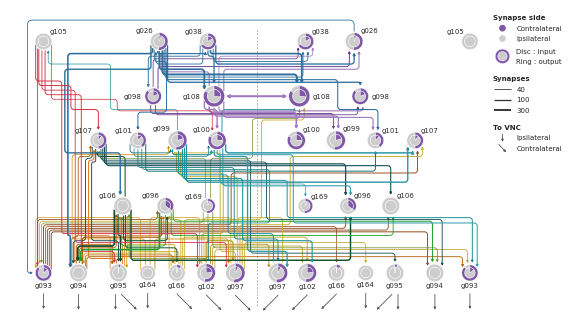

In [99]:
leg_w   = 0.85     # inch, legend column right of the diagram
diag_w  = unit * (x_lim[1] - x_lim[0])
panel_w = diag_w + leg_w

fig = plt.figure(figsize = (panel_w, panel_h))
ax  = fig.add_axes([0, 0, diag_w / panel_w, 1])
ax.set_xlim(*x_lim)
ax.set_ylim(*y_lim)
ax.set_aspect("equal")
ax.axis("off")

#-----------------------------------------------------------------------------
# Midline -- the image is mirrored, so the right LAL is on the left of the page.
# It stops under the fast-route rail.
ax.plot([0, 0], [y_pos["g093"] - 1.1, 8.40],
        color     = "#9a9a9a",
        linestyle = (0, (3, 2)),
        linewidth = 0.5,
        zorder    = 0)

#-----------------------------------------------------------------------------
# Backbone, outputs of the right hemisphere.
# Back to front : descending, local, mixed, hubs, then the input streams.
# lal_rows runs medial -> lateral, so reversed is lateral -> medial. g105 is last.
paint_order = ([g for row in ["Descending", "Local", "Mixed", "Hubs"] for g in reversed(lal_rows[row])]
               + ["g038", "g026", "g105"])
paint_rank  = {g : i for i, g in enumerate(paint_order)}

ordered = sorted(routes, key = lambda r : (paint_rank[r["pre"]], r["synapses"]))
for i, r in enumerate(ordered):
    draw_route(ax, r["points"], r["color"], edge_width(r["synapses"]),
               zorder = 3 + 0.01 * i)

# g108 <-> g108, in the medial hub shade
shrink = (node_r("g108") + 0.04) * unit * 72
ax.add_patch(FancyArrowPatch(node_xy("g108", "Right"), node_xy("g108", "Left"),
                             arrowstyle     = "<|-|>",
                             mutation_scale = arrow_size + 0.20 * edge_width(hub_synapses),
                             linewidth      = edge_width(hub_synapses),
                             color          = edge_colors["g108"],
                             shrinkA        = shrink,
                             shrinkB        = shrink,
                             zorder         = 4))

# g026 and g105, meeting on the right-hemisphere g093
draw_fast_route(ax)

#-----------------------------------------------------------------------------
# Descending output to the VNC -- straight = ipsilateral, slanted = contralateral
stub_gap = 0.42
stub_len = 0.5

def stub(a, x, y, contra, toward):
    a.add_patch(FancyArrowPatch((x, y), (x + (toward * stub_len if contra else 0), y - stub_len),
                                arrowstyle     = "-|>",
                                mutation_scale = 3.2,
                                linewidth      = 0.6,
                                color          = stub_color,
                                shrinkA        = 0,
                                shrinkB        = 0,
                                zorder         = 3))

for hemi in ["Right", "Left"]:
    for g in lal_rows["Descending"]:
        x, y  = node_xy(g, hemi)
        kinds = [pol for pol in ["Ipsi_Descending", "Contra_Descending"] if composition.loc[g, pol] > 0]

        for i, pol in enumerate(kinds):
            dx = 0 if len(kinds) == 1 else outward[hemi] * (0.1 if i == 0 else -0.1)
            stub(ax, x + dx, y - node_r(g) - stub_gap, pol == "Contra_Descending", -outward[hemi])

#-----------------------------------------------------------------------------
# Nodes -- input discs and output rings, labels
for hemi in ["Right", "Left"]:
    for g in lal_groups:
        draw_pie(ax, g, hemi)
        draw_label(ax, g, hemi)

#-----------------------------------------------------------------------------
# Legends, in a column right of the diagram
ax_leg = legend_axes(fig, diag_w / panel_w, leg_w / panel_w)
y = legend_common(ax_leg)

y = legend_title(ax_leg, y + leg_gap, "To VNC")
y = legend_vnc(ax_leg, y, False, "Ipsilateral")
y = legend_vnc(ax_leg, y, True, "Contralateral")

# Save the Figure
plt.savefig("../Figure_Book/Figure_05_LAL-Network.pdf",
            bbox_inches = "tight",
            pad_inches  = 0,
            dpi = 1200)

## Commissural Testing

A node collapses each neuron to a point, so the side of an edge is the side of the somata. A commissural neuron takes inputs on its axonal tuft in the other hemisphere : a local axo-axonic contact there is drawn as a commissural edge, and two commissural axons meeting on the far side are drawn as an ipsilateral one.

`Connectivity_Fragmented_level1` splits every synapse by the fragment it sits on (axon / dendrite, from the `mw axon split` tag or navis) and by the compartment holding the connector. Here each drawn edge of the main panel is split by where its synapses are :

- **onto the axon of the receiving neuron, in the hemisphere opposite its soma** -> dashed. These are the synapses the collapsed node puts on the wrong side.
- **everything else** (dendrites, and axons on the soma side) -> solid. Here the side of the edge is already right.

Same edges as the main panel, nothing recruited. A part is drawn if it is at least 10 synapses (hemisphere-averaged); width follows the part, not the whole edge.

In [100]:
frag = pd.read_parquet("../Data_Connectivity/Connectivity_Fragmented_level1.parquet")
frag = frag.loc[frag["ConnectivityGroup_pre"].isin(lal_groups) &
                frag["ConnectivityGroup_post"].isin(lal_groups)].copy()

frag["Side"] = np.where(frag["Hemisphere_pre"] == frag["Hemisphere_post"], "Ipsi", "Contra")

# Sanity -- summed over fragments and compartments it is the group connectivity of the main panel
keys  = ["ConnectivityGroup_pre", "ConnectivityGroup_post", "Hemisphere_pre", "Hemisphere_post"]
same  = (frag["ConnectivityGroup_pre"] == frag["ConnectivityGroup_post"]) & (frag["Side"] == "Ipsi")
check = (frag.loc[~same].groupby(keys)["weight"].sum()
             .sub(lal_conn.set_index(keys)["weight"], fill_value = 0))
print(f"Group edges that differ from Connectivity_Group : {(check != 0).sum()}")

#------------------------------------------------------------------------------
# Far : onto the receiver's axon, in the hemisphere opposite its soma. Near : everything else.
# Synapses outside every compartment have no hemisphere and stay Near.
syn_hemi     = frag["Compartment"].str.extract(r"_(Left|Right)$")[0]
is_far       = (frag["Fragment_post"] == "axon") & syn_hemi.notna() & (syn_hemi != frag["Hemisphere_post"])
frag["Kind"] = np.where(is_far, "Far", "Near")

# Split every drawn edge, averaged over the two hemispheres
split = (frag.groupby(["ConnectivityGroup_pre", "ConnectivityGroup_post", "Side", "Kind"])["weight"]
             .sum()
             .div(2)
             .unstack("Kind", fill_value = 0)
             .reset_index()
             .rename(columns = {"ConnectivityGroup_pre"  : "Pre",
                                "ConnectivityGroup_post" : "Post"}))

drawn_edges = pd.concat([backbone.assign(Set = "Backbone"),
                         fast.assign(Set = "Fast"),
                         edges.loc[is_hub].assign(Set = "Hub")])
drawn_edges = (drawn_edges.merge(split, on = ["Pre", "Post", "Side"], how = "left")
                          .fillna({"Near" : 0, "Far" : 0}))
drawn_edges["Far_frac"] = drawn_edges["Far"] / drawn_edges["Synapses"]

min_part = 10
print(f"{(drawn_edges['Far'] >= min_part).sum()} of {len(drawn_edges)} edges with a dashed part | "
      f"{drawn_edges['Far'].sum() / drawn_edges['Synapses'].sum():.0%} of the drawn synapses")

(drawn_edges.loc[drawn_edges["Far"] >= min_part, ["Pre", "Post", "Side", "Synapses", "Near", "Far", "Far_frac", "Set"]]
     .sort_values("Far", ascending = False)
     .round(2))

Group edges that differ from Connectivity_Group : 0
19 of 111 edges with a dashed part | 12% of the drawn synapses


,Pre,Post,Side,Synapses,Near,Far,Far_frac,Set
74,g106,g096,Contra,120.0,0.0,120.0,1.00,Backbone
8,g026,g108,Ipsi,157.5,45.0,112.5,0.71,Backbone
90,g108,g100,Ipsi,109.0,40.0,69.0,0.63,Backbone
1,g026,g038,Ipsi,80.5,17.5,63.0,0.78,Backbone
85,g108,g026,Ipsi,71.5,9.0,62.5,0.87,Backbone
82,g107,g096,Contra,96.5,43.5,53.0,0.55,Backbone
21,g094,g093,Contra,42.5,0.0,42.5,1.00,Backbone
47,g099,g100,Ipsi,76.5,34.5,42.0,0.55,Backbone
17,g093,g096,Ipsi,37.0,5.5,31.5,0.85,Backbone
102,g166,g108,Contra,28.5,0.5,28.0,0.98,Backbone


### Taller layout

The split adds lanes between the rows, so the rows sit 15% further apart than in the main panel, and the descending row drops a further 0.5 below that. The input row stays where it is, which keeps the fast-route rail and the top of the midline in place; the diagram unit does not change, so the panel only grows.

The descending groups are spread 15% wider about the midline, and g105 moves out with g093 so it still sits right above it.

The main panel's positions are kept in `y_pos_main` and `x_pos_main` and put back at the end of the section.

In [101]:
stretch    = 1.15     # Row spacing, relative to the main panel
desc_drop  = 0.5      # ... and the descending row this much lower again
desc_wide  = 1.15     # Descending groups spread about the midline
y_pos_main = y_pos.copy()
x_pos_main = x_pos.copy()

# Rows further apart, measured down from the input row
row_y_axo = {row : row_y["Input"] - stretch * (row_y["Input"] - y) for row, y in row_y.items()}
row_y_axo["Descending"] -= desc_drop
y_pos     = {g : row_y_axo[row_of[g]] for g in lal_groups}

# Descending groups wider apart, g105 kept above g093
x_pos = {g : desc_wide * x if row_of[g] == "Descending" else x for g, x in x_pos_main.items()}
x_pos["g105"] = x_pos["g093"]
y_pos_axo, x_pos_axo = y_pos, x_pos

# The limits move out with the descending row; the panel follows, at the same unit
x_grow      = max(abs(x_pos[g]) - abs(x_pos_main[g]) for g in lal_rows["Descending"])
x_lim_axo   = (x_lim[0] - x_grow, x_lim[1] + x_grow)
y_lim_axo   = (y_lim[0] + row_y_axo["Descending"] - row_y["Descending"], y_lim[1])
diag_w_axo  = unit * (x_lim_axo[1] - x_lim_axo[0])
panel_h_axo = unit * (y_lim_axo[1] - y_lim_axo[0])

pd.DataFrame({"x" : x_pos, "y" : y_pos}).loc[["g105"] + lal_rows["Descending"]].round(2)

,x,y
g105,-8.05,8.00
g097,-0.80,-1.24
g102,-1.91,-1.24
g166,-3.01,-1.24
g164,-4.12,-1.24
g095,-5.22,-1.24
g094,-6.73,-1.24
g093,-8.05,-1.24


### Network and routing

One edge per part, in a `MultiDiGraph`, so the solid and dashed parts of an edge each get their own ports, lanes and shaft. The routing is the one above, wrapped in a function so the main panel's `routes` stay untouched. g105 keeps its drop into the open column, spread over as many turns as it has outputs.

In [102]:
G_axo = nx.MultiDiGraph()
for hemi in ["Right", "Left"]:
    for g in lal_groups:
        G_axo.add_node((g, hemi),
                       xy     = node_xy(g, hemi),
                       radius = node_r(g))

for _, e in drawn_edges.loc[drawn_edges["Set"] == "Backbone"].iterrows():
    for kind in ["Near", "Far"]:
        if e[kind] >= min_part:
            G_axo.add_edge((e["Pre"], "Right"), (e["Post"], "Right" if e["Side"] == "Ipsi" else "Left"),
                           synapses = e[kind],
                           color    = edge_color(e["Pre"], e["Post"]),
                           width    = edge_width(e[kind]),
                           dashed   = kind == "Far")

print(G_axo)


def route_graph(graph):
    """
    The routing of the main panel -- routes, shafts, ports, lanes and corners -- for any graph of LAL edges.
    Reads the node positions at call time, so it follows the taller layout.
    """
    #--------------------------------------------------------------------------
    # One route per edge
    routes = []
    for (pre, _), (post, hemi), d in graph.edges(data = True):
        rp = row_order.index(row_of[pre])
        rq = row_order.index(row_of[post])

        if rq > rp:
            out, inn, first_gap, last_gap = "bottom", "top", rp, rq - 1
        elif rq < rp:
            out, inn, first_gap, last_gap = "top", "bottom", rp - 1, rq
        elif row_of[pre] == "Descending":
            out, inn, first_gap, last_gap = "top", "top", rp - 1, rp - 1
        else:
            out, inn, first_gap, last_gap = "bottom", "bottom", rp, rp

        routes.append(dict(pre       = pre,
                           post      = post,
                           hemi      = hemi,
                           synapses  = d["synapses"],
                           color     = d["color"],
                           dashed    = d["dashed"],
                           out       = out,
                           inn       = inn,
                           first_gap = first_gap,
                           last_gap  = last_gap,
                           skips     = first_gap != last_gap,
                           target_x  = node_xy(post, hemi)[0]))

    #--------------------------------------------------------------------------
    # Shafts -- heaviest edges first, each at the free x closest to halfway between its source and target
    placed = []
    for r in sorted(routes, key = lambda r : -r["synapses"]):
        if not r["skips"]:
            continue

        crossed = set(range(min(r["first_gap"], r["last_gap"]) + 1,
                            max(r["first_gap"], r["last_gap"]) + 1))
        target  = (x_pos[r["pre"]] + r["target_x"]) / 2

        best, best_cost = None, np.inf
        for x in np.arange(-6.4, 6.41, 0.02):
            if any(a < x < b for k in crossed for a, b in blocked[k]):
                continue
            if any(abs(x - sx) < shaft_sep and crossed & rows for sx, rows in placed):
                continue

            cost = abs(x - target) + 5 * sum(a < x < b for k in crossed for a, b in avoid[k])
            if cost < best_cost:
                best, best_cost = x, cost

        r["shaft"] = best
        placed.append((best, crossed))

    #--------------------------------------------------------------------------
    # Ports -- one per route on its source and on its target, ordered left to right by where the route heads
    attached = defaultdict(list)
    for i, r in enumerate(routes):
        attached[(r["pre"], "Right", r["out"])].append((("out", i), first_x(r)))
        came_from = r["shaft"] if r["skips"] else x_pos[r["pre"]]
        attached[(r["post"], r["hemi"], r["inn"])].append((("in", i), came_from))

    ports = {}
    for (g, hemi, side), items in attached.items():
        items  = sorted(items, key = lambda item : item[1])
        n      = len(items)
        centre = node_xy(g, hemi)
        radius = node_r(g)
        sign   = 1 if side == "top" else -1
        limit  = top_span if side == "top" and has_corner_label(g) else port_span
        span   = min(limit * radius, port_step * (n - 1) / 2)

        for j, (port, _) in enumerate(items):
            dx = 0 if n == 1 else -span + 2 * span * j / (n - 1)
            dy = np.sqrt(radius ** 2 - dx ** 2)
            ports[port] = (centre[0] + dx, centre[1] + sign * dy, sign)

    #--------------------------------------------------------------------------
    # Lanes -- packed so that no two horizontals in a gap overlap, the tracks spread evenly through the gap
    spans = defaultdict(dict)
    for i, r in enumerate(routes):
        start = ports[("out", i)][0]
        end   = ports[("in", i)][0]

        if r["skips"]:
            spans[r["first_gap"]][("first", i)] = sorted([start, r["shaft"]])
            spans[r["last_gap"]][("last", i)]   = sorted([r["shaft"], end])
        else:
            spans[r["first_gap"]][("first", i)] = sorted([start, end])

    lane_y = {}
    for gap, lanes in sorted(spans.items()):
        tracks = []
        slot   = {}
        for lane, (lo, hi) in sorted(lanes.items(), key = lambda item : (item[1][0], -item[1][1])):
            for t, track in enumerate(tracks):
                if all(hi + lane_sep < a or lo - lane_sep > b for a, b in track):
                    track.append((lo, hi))
                    slot[lane] = t
                    break
            else:
                tracks.append([(lo, hi)])
                slot[lane] = len(tracks) - 1

        y_lo, y_hi = gap_span(gap)
        for lane, t in slot.items():
            lane_y[(gap, lane)] = y_hi - (y_hi - y_lo) * (t + 0.5) / len(tracks)

        print(f"Gap {row_order[gap]} -> {row_order[gap + 1]} : {len(tracks)} tracks")

    #--------------------------------------------------------------------------
    # Corner points of every route
    for i, r in enumerate(routes):
        px, py, ps = ports[("out", i)]
        qx, qy, qs = ports[("in", i)]
        start = (px, py + ps * 0.03)
        end   = (qx, qy + qs * 0.07)
        y0    = lane_y[(r["first_gap"], ("first", i))]

        if r["skips"]:
            y1 = lane_y[(r["last_gap"], ("last", i))]
            r["points"] = [start, (px, y0), (r["shaft"], y0), (r["shaft"], y1), (qx, y1), end]
        else:
            r["points"] = [start, (px, y0), (qx, y0), end]

    #--------------------------------------------------------------------------
    # g105 -- straight down into the open column, and only then across to the shaft.
    # The turns keep the band they had around the hubs, one per output.
    hub_y       = y_pos["g098"]
    g105_routes = sorted((r for r in routes if r["pre"] == "g105" and r["skips"]),
                         key = lambda r : r["points"][0][0])
    turns       = np.linspace(hub_y + 0.50, hub_y - 0.10, max(len(g105_routes), 2))

    for r, y_turn in zip(g105_routes, turns):
        start = r["points"][0]
        px    = start[0]
        shaft = r["shaft"]
        y1    = r["points"][3][1]
        qx    = r["points"][4][0]
        end   = r["points"][5]
        r["points"] = [start, (px, y_turn), (shaft, y_turn),
                       (shaft, y1), (qx, y1), end]

    return routes


routes_axo = route_graph(G_axo)

MultiDiGraph with 38 nodes and 121 edges
Gap Input -> Hubs : 16 tracks
Gap Hubs -> Mixed : 9 tracks
Gap Mixed -> Local : 23 tracks
Gap Local -> Descending : 26 tracks


### Axo Figure Panel

The main panel with every edge split : dashed for synapses onto the receiver's axon on the far side of its soma, solid for the rest. The fast routes (g026 / g105 -> g093) have no far-side part and stay as they are. g108 <-> g108 keeps a dashed twin just below it only if its far-side part reaches 10 synapses.

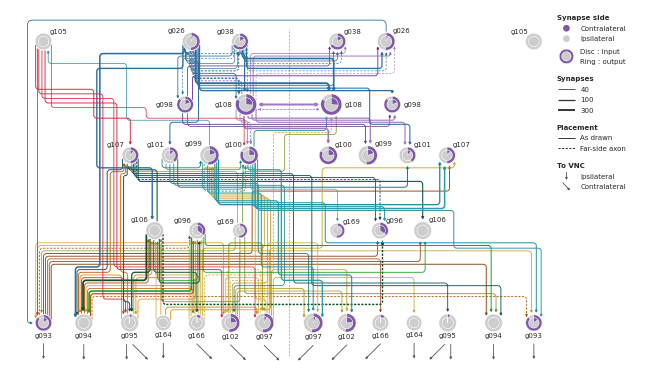

In [103]:
def dash_style(width, on = 1.6, off = 1.0):
    """
    Dashes in points, whatever the line width -- matplotlib scales them by it.
    """
    return (0, (on / width, off / width))


def draw_route_axo(a, points, color, width, dashed, zorder = 3):
    """
    draw_route, with a dashed shaft and a solid head for the far-side axonic parts.
    """
    if not dashed:
        draw_route(a, points, color, width, zorder = zorder)
        return

    a.add_patch(FancyArrowPatch(path       = rounded(points),
                                arrowstyle = "-",
                                linewidth  = width,
                                linestyle  = dash_style(width),
                                color      = color,
                                capstyle   = "butt",
                                shrinkA    = 0,
                                shrinkB    = 0,
                                zorder     = zorder))

    # Solid head on the last bit of the final leg
    tip  = np.asarray(points[-1], float)
    back = np.asarray(points[-2], float) - tip
    base = tip + back / np.linalg.norm(back) * min(0.12, 0.9 * np.linalg.norm(back))
    a.add_patch(FancyArrowPatch(base, tip,
                                arrowstyle     = "-|>",
                                mutation_scale = arrow_size + 0.20 * width,
                                linewidth      = width,
                                color          = color,
                                capstyle       = "butt",
                                shrinkA        = 0,
                                shrinkB        = 0,
                                zorder         = zorder))

#------------------------------------------------------------------------------
panel_w_axo = diag_w_axo + leg_w

fig = plt.figure(figsize = (panel_w_axo, panel_h_axo))
ax  = fig.add_axes([0, 0, diag_w_axo / panel_w_axo, 1])
ax.set_xlim(*x_lim_axo)
ax.set_ylim(*y_lim_axo)
ax.set_aspect("equal")
ax.axis("off")

# Midline -- it stops under the fast-route rail
ax.plot([0, 0], [y_pos["g093"] - 1.1, 8.40],
        color     = "#9a9a9a",
        linestyle = (0, (3, 2)),
        linewidth = 0.5,
        zorder    = 0)

#-----------------------------------------------------------------------------
# Backbone parts, same paint order as the main panel
ordered = sorted(routes_axo, key = lambda r : (paint_rank[r["pre"]], r["synapses"]))
for i, r in enumerate(ordered):
    draw_route_axo(ax, r["points"], r["color"], edge_width(r["synapses"]), r["dashed"],
                   zorder = 3 + 0.01 * i)

# g108 <-> g108 -- solid part on the centre line, dashed part just below
hub    = drawn_edges.loc[drawn_edges["Set"] == "Hub"].iloc[0]
shrink = (node_r("g108") + 0.04) * unit * 72
for kind, dy in [("Near", 0.0), ("Far", -0.16)]:
    if hub[kind] < min_part:
        continue
    w = edge_width(hub[kind])
    ax.add_patch(FancyArrowPatch(node_xy("g108", "Right") + [0, dy], node_xy("g108", "Left") + [0, dy],
                                 arrowstyle     = "<|-|>",
                                 mutation_scale = arrow_size + 0.20 * w,
                                 linewidth      = w,
                                 linestyle      = dash_style(w) if kind == "Far" else "-",
                                 color          = edge_colors["g108"],
                                 shrinkA        = shrink,
                                 shrinkB        = shrink,
                                 zorder         = 4))

draw_fast_route(ax)

#-----------------------------------------------------------------------------
# VNC stubs and nodes, as in the main panel
for hemi in ["Right", "Left"]:
    for g in lal_rows["Descending"]:
        x, y  = node_xy(g, hemi)
        kinds = [pol for pol in ["Ipsi_Descending", "Contra_Descending"] if composition.loc[g, pol] > 0]

        for i, pol in enumerate(kinds):
            dx = 0 if len(kinds) == 1 else outward[hemi] * (0.1 if i == 0 else -0.1)
            stub(ax, x + dx, y - node_r(g) - stub_gap, pol == "Contra_Descending", -outward[hemi])

for hemi in ["Right", "Left"]:
    for g in lal_groups:
        draw_pie(ax, g, hemi)
        draw_label(ax, g, hemi)

#-----------------------------------------------------------------------------
# Legends
ax_leg = legend_axes(fig, diag_w_axo / panel_w_axo, leg_w / panel_w_axo)
y = legend_common(ax_leg)

y = legend_title(ax_leg, y + leg_gap, "Placement")
y = legend_line(ax_leg, y, "As drawn", edge_width(60))
y = legend_line(ax_leg, y, "Far-side axon", edge_width(60), dashed = True)

y = legend_title(ax_leg, y + leg_gap, "To VNC")
y = legend_vnc(ax_leg, y, False, "Ipsilateral")
y = legend_vnc(ax_leg, y, True, "Contralateral")

# Save the Figure
plt.savefig("../Figure_Book/Figure_05_LAL-Network-Axonal-Lines.pdf",
            bbox_inches = "tight",
            pad_inches  = 0,
            dpi = 1200)

# Back to the main panel's layout
y_pos = y_pos_main
x_pos = x_pos_main

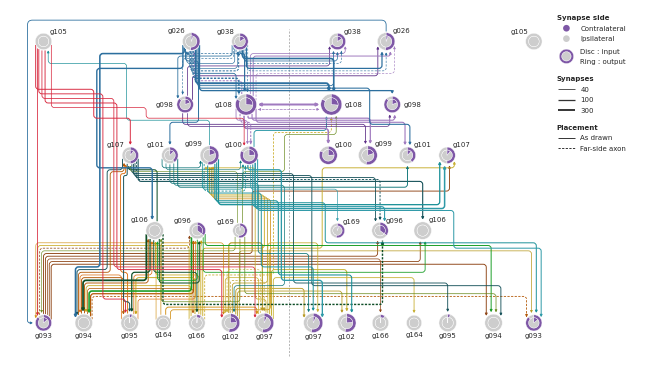

In [104]:
# The axo panel again, without the VNC stubs -- in the taller layout
y_pos = y_pos_axo
x_pos = x_pos_axo

#------------------------------------------------------------------------------
panel_w_axo = diag_w_axo + leg_w

fig = plt.figure(figsize = (panel_w_axo, panel_h_axo))
ax  = fig.add_axes([0, 0, diag_w_axo / panel_w_axo, 1])
ax.set_xlim(*x_lim_axo)
ax.set_ylim(*y_lim_axo)
ax.set_aspect("equal")
ax.axis("off")

# Midline -- it stops under the fast-route rail
ax.plot([0, 0], [y_pos["g093"] - 1.1, 8.40],
        color     = "#9a9a9a",
        linestyle = (0, (3, 2)),
        linewidth = 0.5,
        zorder    = 0)

#-----------------------------------------------------------------------------
# Backbone parts, same paint order as the main panel
ordered = sorted(routes_axo, key = lambda r : (paint_rank[r["pre"]], r["synapses"]))
for i, r in enumerate(ordered):
    draw_route_axo(ax, r["points"], r["color"], edge_width(r["synapses"]), r["dashed"],
                   zorder = 3 + 0.01 * i)

# g108 <-> g108 -- solid part on the centre line, dashed part just below
hub    = drawn_edges.loc[drawn_edges["Set"] == "Hub"].iloc[0]
shrink = (node_r("g108") + 0.04) * unit * 72
for kind, dy in [("Near", 0.0), ("Far", -0.16)]:
    if hub[kind] < min_part:
        continue
    w = edge_width(hub[kind])
    ax.add_patch(FancyArrowPatch(node_xy("g108", "Right") + [0, dy], node_xy("g108", "Left") + [0, dy],
                                 arrowstyle     = "<|-|>",
                                 mutation_scale = arrow_size + 0.20 * w,
                                 linewidth      = w,
                                 linestyle      = dash_style(w) if kind == "Far" else "-",
                                 color          = edge_colors["g108"],
                                 shrinkA        = shrink,
                                 shrinkB        = shrink,
                                 zorder         = 4))

draw_fast_route(ax)

#-----------------------------------------------------------------------------
# Nodes, as in the main panel
for hemi in ["Right", "Left"]:
    for g in lal_groups:
        draw_pie(ax, g, hemi)
        draw_label(ax, g, hemi)

#-----------------------------------------------------------------------------
# Legends
ax_leg = legend_axes(fig, diag_w_axo / panel_w_axo, leg_w / panel_w_axo)
y = legend_common(ax_leg)

y = legend_title(ax_leg, y + leg_gap, "Placement")
y = legend_line(ax_leg, y, "As drawn", edge_width(60))
y = legend_line(ax_leg, y, "Far-side axon", edge_width(60), dashed = True)

# Save the Figure
plt.savefig("../Figure_Book/Figure_05_LAL-Network-Axonal-Lines_No-VNC.pdf",
            bbox_inches = "tight",
            pad_inches  = 0,
            dpi = 1200)

# Back to the main panel's layout
y_pos = y_pos_main
x_pos = x_pos_main

# <center>**हो गया दोस्तों!**</center>